# Ejercicios de Seaborn

# 1. Importa pandas, pyplot y seaborn

In [137]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Lee 'Pokemon.csv', lee la primera columna del csv como índice del DataFrame

In [138]:
pokemon = pd.read_csv('./data/Pokemon.csv')


In [139]:
indice = pokemon['#']
indice

0        1
1        2
2        3
3        4
4        5
      ... 
146    147
147    148
148    149
149    150
150    151
Name: #, Length: 151, dtype: int64

# 4. Mira las primeras filas del dataset para hacerte una idea de los datos cargados

In [140]:
pokemon.head()

,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Stage,Legendary
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,2,False
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,3,False
3,4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False
4,5,Charmeleon,Fire,NaN,405,58,64,58,80,65,80,2,False


# 5. Haz un scatter plot con lmplot(), que es el método que pinta una regresión lineal
### Pasa el DataFrame como argumento del método en el parámetro llamado data

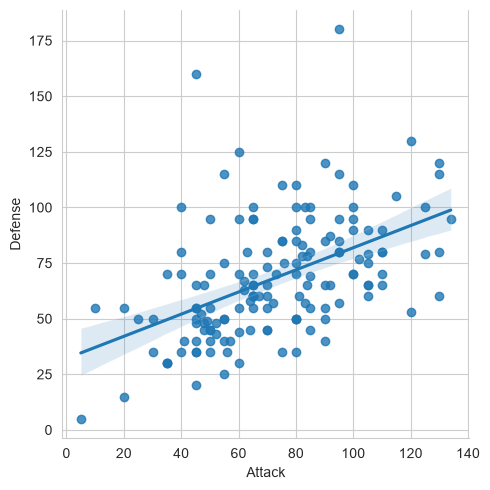

In [141]:
sns.lmplot(data=pokemon, x='Attack', y='Defense');

# 6. No queremos ver la línea recta de la regresión lineal.
### prueba a añadir fit_reg a falso

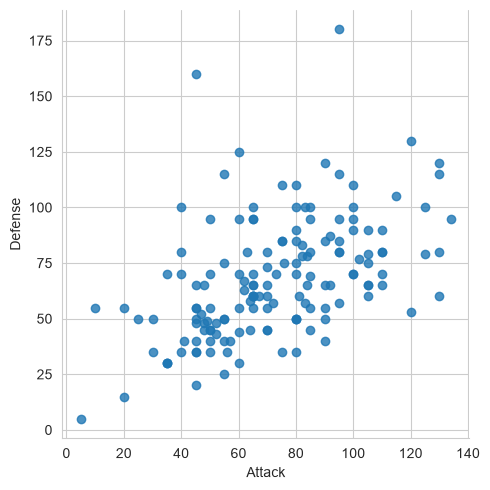

In [142]:
sns.lmplot(data=pokemon, x='Attack', y='Defense', fit_reg=False);

# 7. Vamos a decir qué variable (columna del DataFrame) codifica los colores (hue)
### Que el hue sea el Stage

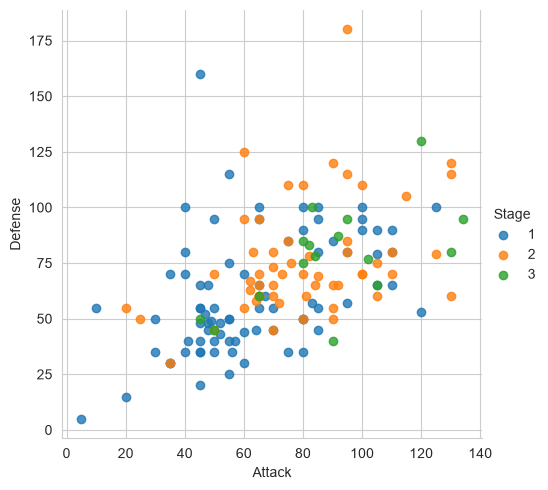

In [143]:
sns.lmplot(data=pokemon, x='Attack', y='Defense', fit_reg=False, hue='Stage');

# 8. Limita el eje x entre 20 y 100

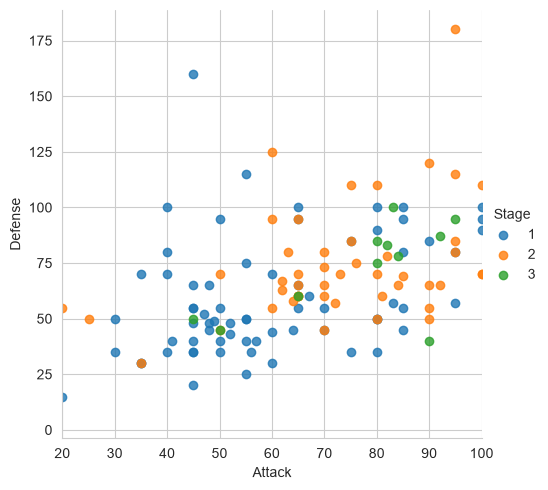

In [144]:
sns.lmplot(data=pokemon, x='Attack', y='Defense', fit_reg=False, hue='Stage')
plt.xlim(20,100);

# 9. Dibuja un diagrama de cajas con el dataframe

<Axes: >

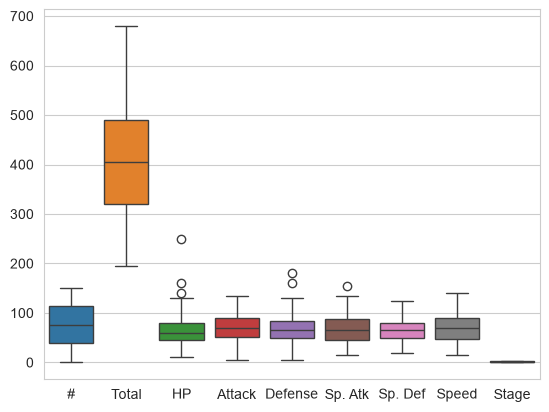

In [145]:
sns.boxplot(data=pokemon.select_dtypes(include=['number']))

# 10. No nos interesan las columnas Total, Stage ni Legendary
### Bórralos del DataFrame y vuelve a dibujar el diagrama de cajas

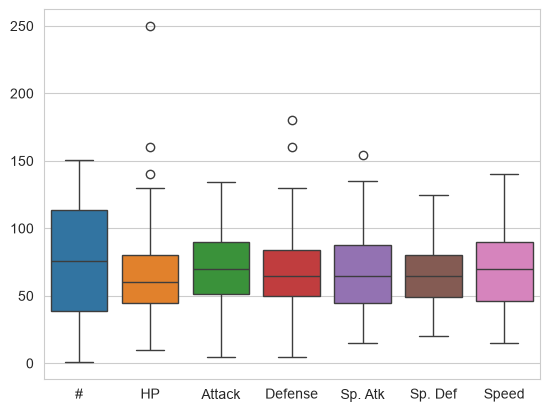

In [146]:
pokemon_filtrado_10 = pokemon.drop(columns=['Total', 'Stage', 'Legendary'], errors='ignore')
sns.boxplot(data=pokemon_filtrado_10.select_dtypes(include=['number']));

# 11. Mira cuántos 'Type 1' diferentes hay en el DataFrame

In [147]:
pokemon['Type 1'].nunique()

15

# 12. Quédate del Dataframe solo con los 'Type 1' iguales a 'Grass', 'Fire' o 'Water'

In [148]:
df_grass_fire_water = pokemon[pokemon['Type 1'].isin(['Grass', 'Fire', 'Water'])]

# 13. Usa un estilo 'whitegrid'

In [149]:
sns.set_style('whitegrid')

# 14. Pinta diagramas de violín con el DataFrame filtrado por los 3 tipos

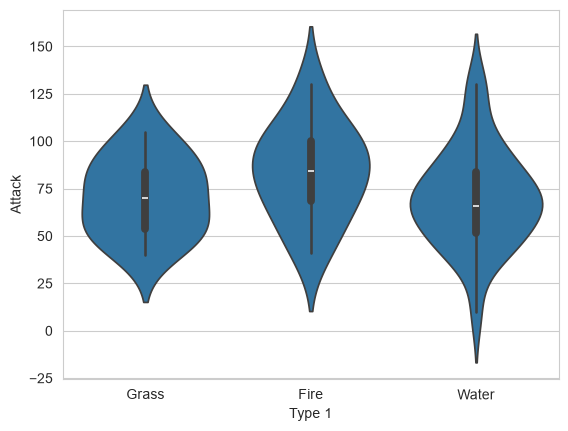

In [150]:
sns.violinplot(data=df_grass_fire_water, x='Type 1', y='Attack');

# 15. Escribe una lista de colores con valores '#78C850', '#F08030',  '#6890F0'

In [151]:
colores = ['#78C850', '#F08030', '#6890F0' ]

# 16. Pinta de nuevo los diagramas de violín añadiendo esos colores en la paleta (palette)

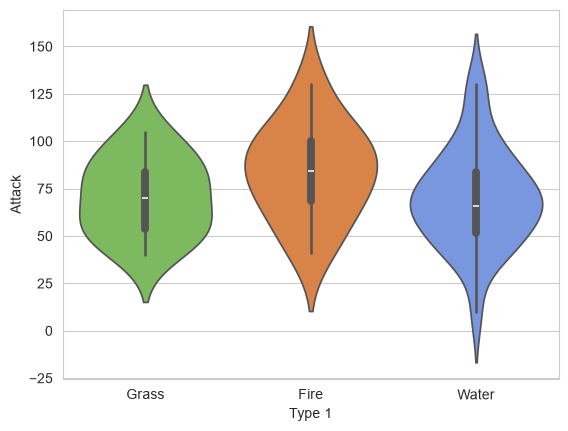

In [152]:
sns.violinplot(data=df_grass_fire_water, x='Type 1', y='Attack', hue='Type 1', palette=colores, legend=False);

# 17. Con el diagrama de violín vemos la forma de la distribución, pero no sabemos si Grass tiene muchos puntos y Fire tiene muy pocos.
### Para ver esto, usamos el swarmplot.
### Pinta el último diagrama de violines pero con un swarmplot en lugar de un violin

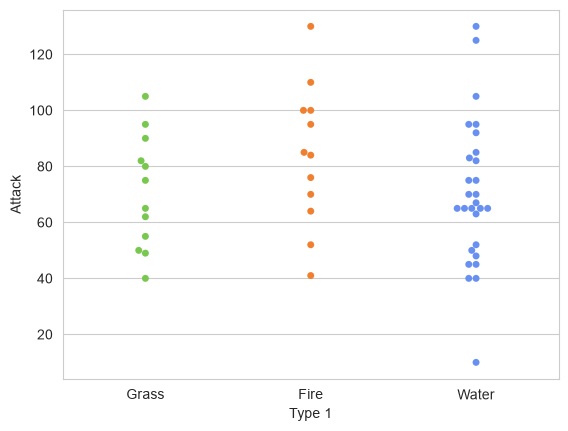

In [153]:
sns.swarmplot(data=df_grass_fire_water, x='Type 1', y='Attack', hue='Type 1', palette=colores, legend=False);

# 18. Queremos ver los violines a la vez que los swarm, los podemos pintar juntos. 
### Elimina los diagramas de caja dentro de los violines con el parámetro inner = None y pon una transparencia de 0.9 en el swarmplot
### Pon un título con pyplot (como siempre)

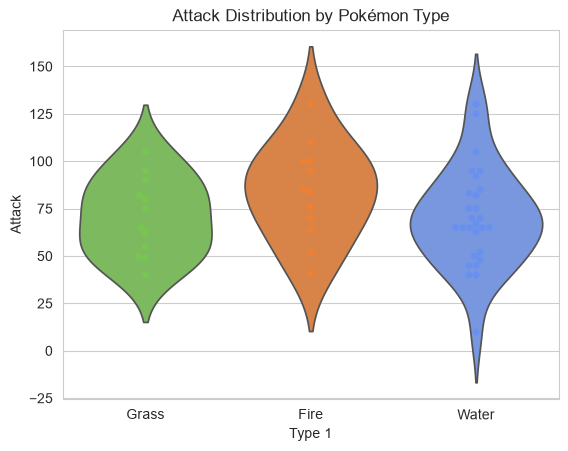

In [154]:
sns.violinplot(data=df_grass_fire_water, x='Type 1', y='Attack', hue='Type 1', palette=colores, legend=False, inner=None)
sns.swarmplot(data=df_grass_fire_water, x='Type 1', y='Attack', hue='Type 1', palette=colores, legend=False, alpha=0.9)
plt.title('Attack Distribution by Pokémon Type');

# 19. Veamos la función melt() de pandas. Melt toma los valores de varias columnas y los junta todos en una misma columna nueva.
### Dado un DataFrame, melt recibe varios parámetros:
### * qué columnas del DataFrame se quedan igual
### * qué nombres de columnas del dataframe pasan a ser una columna nueva
### * cómo queremos llamar esas nuevas columnas

### Primero recuerda el Dataframe df_grass_fire_water con las primeras 5 filas

In [155]:
df_grass_fire_water.head(5)

,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Stage,Legendary
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,2,False
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,3,False
3,4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False
4,5,Charmeleon,Fire,NaN,405,58,64,58,80,65,80,2,False


# 20. Queremos dejar igual las variables 'Name' y 'Type 1'
### Queremos añadir una columa nueva cuyos valores sean las columnas que queremos apilar y que se llame 'New Column'
### Escribimos df_gfw.melt(id_vars=['Name', 'Type 1'], value_vars=[...], var_name='New Column')

In [156]:
df_melted = df_grass_fire_water.melt(id_vars=['Name', 'Type 1'], value_vars=['HP', 'Attack', 'Defense', 'Sp. Atk', 'Sp. Def', 'Speed'], var_name='New Column')
df_melted.head(5)


,Name,Type 1,New Column,value
0,Bulbasaur,Grass,HP,45
1,Ivysaur,Grass,HP,60
2,Venusaur,Grass,HP,80
3,Charmander,Fire,HP,39
4,Charmeleon,Fire,HP,58


# 21. Pintamos el swarmplot con el melted y entendemos la información

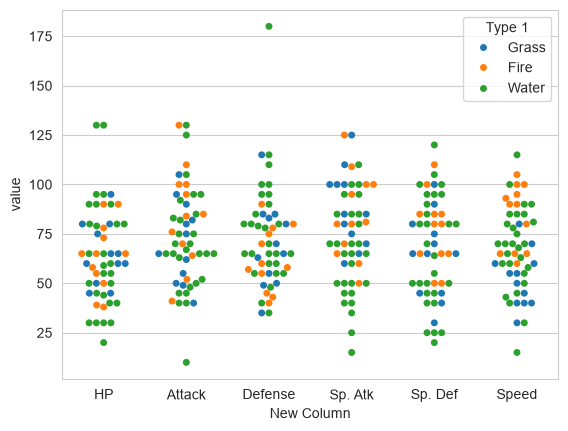

In [157]:
sns.swarmplot(data=df_melted, x='New Column', y='value', hue='Type 1');

# 22. Basándote en el gráfico anterior, define el tamaño de la figura en (10,6) (usa plt)
### En el swarmplot añade el argumento dodge a True y usa la anterior paleta de colores Pokemon

### Dodge en inglés es "esquivar", ¿qué diferencia ves?

## Usando plt 
### fija el límite del eje Y entre 0 y 200
### fija la leyenda con bbox_to_anchor en upper left. Pista: upper left es el código 2 y se usa el parámetro loc.

### Observa que incluso usando Seaborn, usamos Pyplot para trabajar con los ejes, la leyenda y el tamaño
### Lo importante es que Seaborn y Pyplot conviven bien juntos

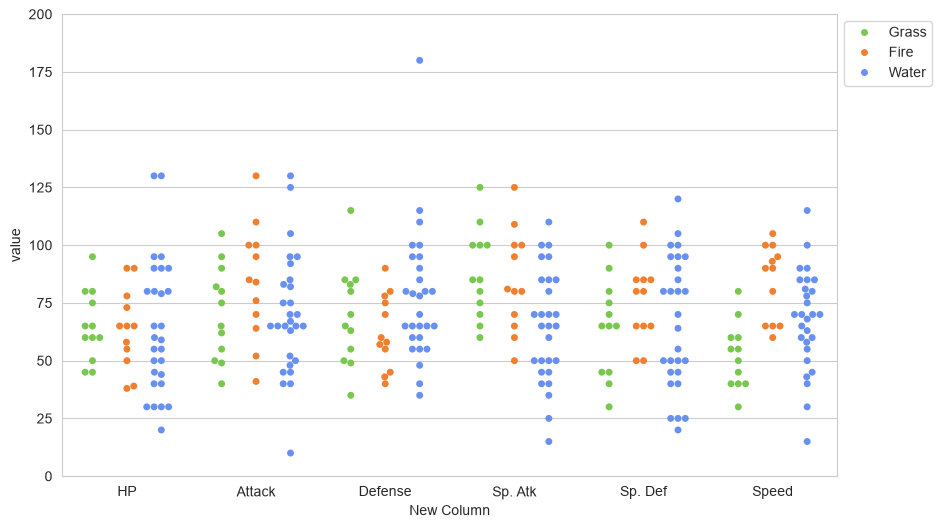

In [158]:
plt.figure(figsize=(10, 6))
sns.swarmplot(data=df_melted, x='New Column', y='value', hue='Type 1', palette=colores, dodge=True)
plt.ylim(0, 200)
plt.legend(bbox_to_anchor=(1,1), loc=2);   #loc=2 equivale a 'upper left'

# 23. Mapas de calor
### Calcula las correlaciones del primer DataFrame original df
### Pista: las correlaciones se calculan con el método corr()
### Recuerda: las correlaciones miden entre dos variables, si varío una, cuánto me varía la otra (cómo están de relacionadas)

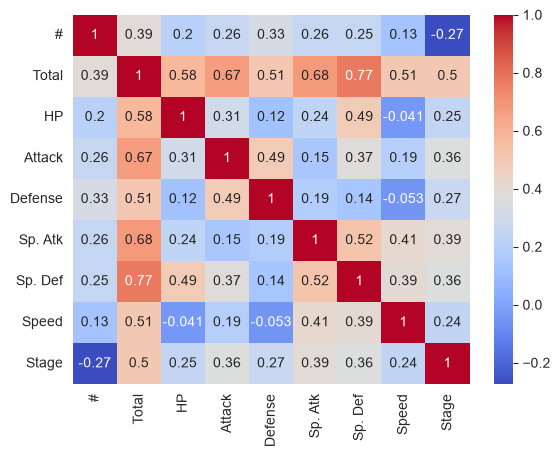

In [159]:
#primero calculo la matriz de correlación, solo tengo en cuenta las columnas numéricas
corr_matrix = pokemon.select_dtypes(include=['number']).corr()
#Mapa de calor
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm');


### ¿la correlación entre qué valores se encuentra?
### la autocorrelación es la correlación de una variable consigo misma, ¿qué aprecias?
### Encuentra dos variables que veas que están fuertemente relacionadas según la correlación

## Respuesta:  
##### Las correlaciones están entre -0.27 y 0.77.  
##### La autocorrelación siempre da 1.  
##### Las dos vbles más fuertemente relacionadas son Sp. Def y Sp. Atk con 0.52, no considero las que tienen en cuenta el total ya que es la suma de todas las vbles numéricas

# 24. Pinta el histograma y la densidad de probabilidad del nivel de defensa usando el DataFrame original

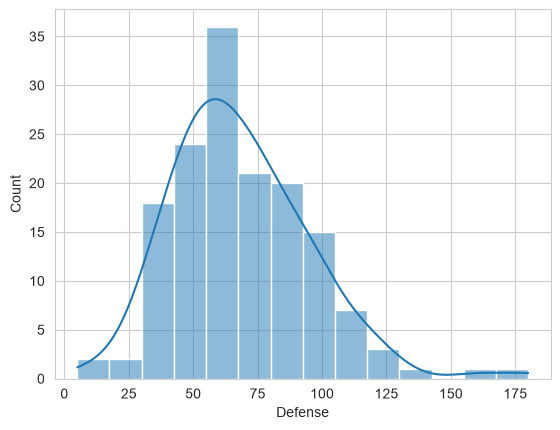

In [160]:
sns.histplot(data=pokemon, x='Defense', kde=True);

# 25. Pinta un diagrama de barras de la columna 'Type 1' usando el DataFrame original
### Usa un sns.countplot
### Usa plt.xticks y gira las etiquetas

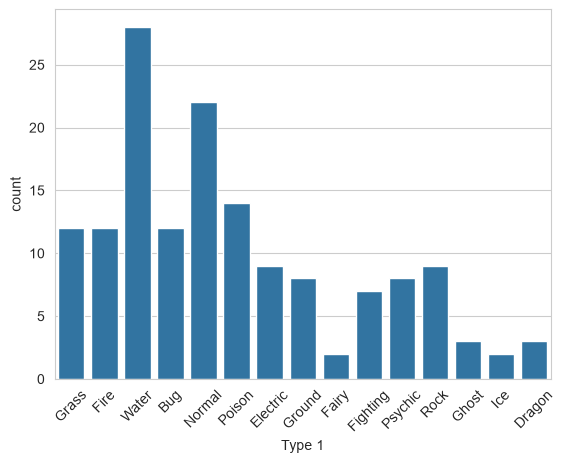

In [161]:
sns.countplot(data=pokemon, x='Type 1')
plt.xticks(rotation=45);

# 26. Usa catplot con el DataFrame original.
### Muestra el valor de Defense según el 'Type 1', muestra un subplot para legendarios y otro para no legendarios y divide los colores según el Type 2

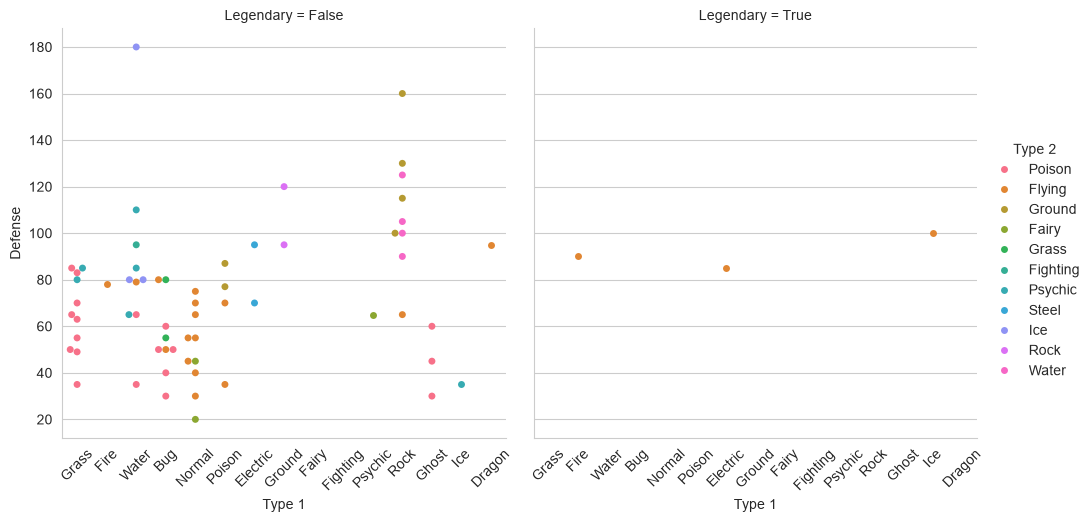

In [162]:
pokemon_26 = sns.catplot(data=pokemon, x='Type 1', y='Defense', hue='Type 2', col='Legendary', kind='swarm')
pokemon_26.set_xticklabels(rotation=45);

# 27. Muestra una función distribución de probabilidad con kdeplot (curvas de nivel) de la defensa respecto al ataque.
### Di un bin 2D donde caigan muchos puntos (ataque, defensa).

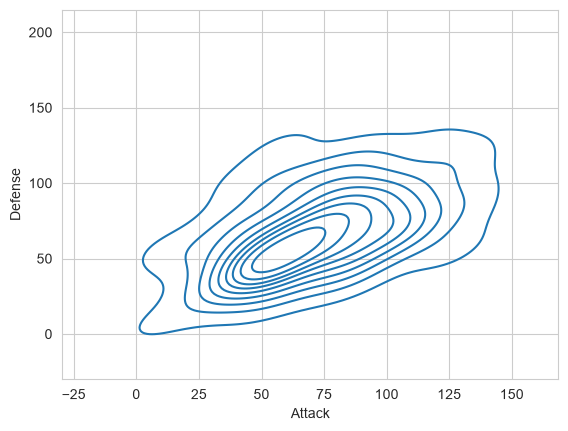

In [163]:
sns.kdeplot(data=pokemon, x='Attack', y='Defense');

In [164]:
#Bin 50-75 Attack-Defense

# 28. Pinta una distribución de probabilidad conjunta con jointplot, pintando la defensa respecto al ataque del DataFrame original

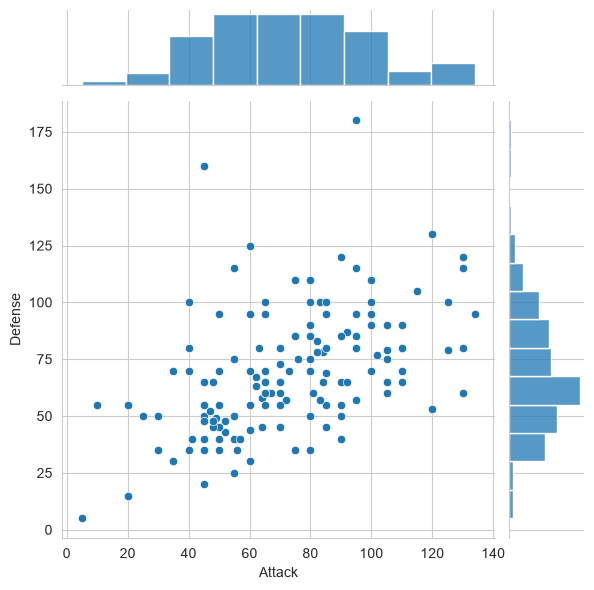

In [165]:
sns.jointplot(data=pokemon, x='Attack', y='Defense', kind='scatter');